<a href="https://colab.research.google.com/github/AlfCR/dnn-estadia/blob/main/notebooks/V_A_P_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Validación Cruzada - Modelo de LSTM


In [ ]:
#Celda 1
from google.colab import drive
drive.mount('/content/drive')

# Clonar el repositorio para traer el archivo modelos.py
!git clone https://github.com/AlfCR/dnn-estadia.git
%cd dnn-estadia
!git pull

import sys
sys.path.append('/content/dnn-estadia/src')
import numpy as np
import tensorflow as tf
from modelos import crear_modelo, obtener_callbacks
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

tf.random.set_seed(42)
np.random.seed(42)
print("Entorno de LSTM configurado correctamente.")

Mounted at /content/drive
Cloning into 'dnn-estadia'...
remote: Enumerating objects: 97, done.
remote: Counting objects: 100% (97/97), done.
remote: Compressing objects: 100% (79/79), done.
remote: Total 97 (delta 37), reused 46 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (97/97), 232.82 KiB | 4.56 MiB/s, done.
Resolving deltas: 100% (37/37), done.
/content/dnn-estadia
Already up to date.
Entorno de LSTM configurado correctamente.


In [ ]:
#Celda 2 CARGAR EL DATASET

ruta = '/content/drive/MyDrive/Colab Notebooks/dataset/dataset_limpio/dataset_preparado_3d.npz'
datos = np.load(ruta)
X_train = datos['X_train']
y_train = datos['y_train']

X_val = datos['X_val']
y_val = datos['y_val']

X_test = datos['X_test']
y_test = datos['y_test']

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (6959, 30, 23)
y_train: (6959,)
X_val: (1343, 30, 23)
y_val: (1343,)
X_test: (2342, 30, 23)
y_test: (2342,)


In [ ]:
# Celda 3
tscv = TimeSeriesSplit(n_splits=5) #Validaciones independientes (5)

for fold, (train_idx, val_idx) in enumerate(
        tscv.split(X_train),
        start=1):

    print(f"\n FOLD {fold} ")

    print("Primer índice train:", train_idx[0])
    print("Último índice train:", train_idx[-1])

    print("Primer índice val:", val_idx[0])
    print("Último índice val:", val_idx[-1])

    print("Tamaño train:", len(train_idx))
    print("Tamaño val:", len(val_idx))


 FOLD 1 
Primer índice train: 0
Último índice train: 1163
Primer índice val: 1164
Último índice val: 2322
Tamaño train: 1164
Tamaño val: 1159

 FOLD 2 
Primer índice train: 0
Último índice train: 2322
Primer índice val: 2323
Último índice val: 3481
Tamaño train: 2323
Tamaño val: 1159

 FOLD 3 
Primer índice train: 0
Último índice train: 3481
Primer índice val: 3482
Último índice val: 4640
Tamaño train: 3482
Tamaño val: 1159

 FOLD 4 
Primer índice train: 0
Último índice train: 4640
Primer índice val: 4641
Último índice val: 5799
Tamaño train: 4641
Tamaño val: 1159

 FOLD 5 
Primer índice train: 0
Último índice train: 5799
Primer índice val: 5800
Último índice val: 6958
Tamaño train: 5800
Tamaño val: 1159


In [ ]:
# Celda 4 PRIMER ENTRENAMIENTO DENTRO DE LOS FOLDS

rmse_folds = []
mae_folds = []
r2_folds = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train),start=1):

    print(f"\n FOLD {fold} ")

    X_tr = X_train[train_idx]
    y_tr = y_train[train_idx]

    X_val_fold = X_train[val_idx]
    y_val_fold = y_train[val_idx]

    modelo = crear_modelo(tipo = 'LSTM')


    modelo.fit(X_tr, y_tr, epochs=100, batch_size=64, validation_data=(X_val_fold, y_val_fold), callbacks=obtener_callbacks(), verbose=0)

    y_pred = modelo.predict(X_val_fold, verbose=0).flatten()

    rmse = np.sqrt(mean_squared_error(y_val_fold, y_pred))
    rmse_folds.append(rmse)

    mae = mean_absolute_error(y_val_fold, y_pred)
    mae_folds.append(mae)

    r2 = r2_score(y_val_fold, y_pred)
    r2_folds.append(r2)

    print(f"RMSE: {rmse:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"R2: {r2:.4f}")



 FOLD 1 
Epoch 16: early stopping
Restoring model weights from the end of the best epoch: 6.
RMSE: 0.9792
MAE: 0.6880
R2: 0.2984

 FOLD 2 
Epoch 14: early stopping
Restoring model weights from the end of the best epoch: 4.
RMSE: 0.7105
MAE: 0.5435
R2: 0.2939

 FOLD 3 
Epoch 13: early stopping
Restoring model weights from the end of the best epoch: 3.
RMSE: 0.8358
MAE: 0.6121
R2: 0.2546

 FOLD 4 
Epoch 14: early stopping
Restoring model weights from the end of the best epoch: 4.
RMSE: 0.7525
MAE: 0.5547
R2: 0.2603

 FOLD 5 
Epoch 13: early stopping
Restoring model weights from the end of the best epoch: 3.
RMSE: 0.8543
MAE: 0.6040
R2: 0.3972


In [ ]:
print("\nRESULTADOS")

print(f"RMSE promedio: {np.mean(rmse_folds):.4f}")
print(f"RMSE std: {np.std(rmse_folds):.4f}")

print(f"MAE promedio: {np.mean(mae_folds):.4f}")
print(f"MAE std: {np.std(mae_folds):.4f}")

print(f"R² promedio: {np.mean(r2_folds):.4f}")
print(f"R² std: {np.std(r2_folds):.4f}")


RESULTADOS
RMSE promedio: 0.8265
RMSE std: 0.0929
MAE promedio: 0.6005
MAE std: 0.0513
R² promedio: 0.3009
R² std: 0.0512


In [ ]:
import os
import pandas as pd

# 1. Definir la ruta de destino
directorio_destino = '/content/drive/MyDrive/Colab Notebooks/dataset/v_a_p_LSTM'
os.makedirs(directorio_destino, exist_ok=True)
ruta_archivo = os.path.join(directorio_destino, 'resultados_LSTM.csv')

# 2. Estructurar los datos de los folds
data = {
    'Fold': [f'Fold {i}' for i in range(1, len(rmse_folds) + 1)],
    'RMSE': [float(r) for r in rmse_folds],
    'MAE': [float(m) for m in mae_folds],
    'R2': [float(r) for r in r2_folds]
}

# Crear el DataFrame inicial
df_resultados = pd.DataFrame(data)

# 3. Calcular filas adicionales para Promedio y Desviación Estándar
fila_promedio = {
    'Fold': 'Promedio',
    'RMSE': round(np.mean(rmse_folds), 4),
    'MAE': round(np.mean(mae_folds), 4),
    'R2': round(np.mean(r2_folds), 4),
}

fila_std = {
    'Fold': 'Desviación Estándar',
    'RMSE': round(np.std(rmse_folds), 4),
    'MAE': round(np.std(mae_folds), 4),
    'R2': round(np.std(r2_folds), 4),
}

# Añadir las filas al DataFrame
df_resultados = pd.concat([df_resultados, pd.DataFrame([fila_promedio, fila_std])], ignore_index=True)

# Datos en excel
ruta_excel = os.path.join(directorio_destino, 'resultados_LSTM.xlsx')
df_resultados.to_excel(ruta_excel, index=False)
print(f"Tabla de resultados guardada exitosamente en:\n{ruta_excel}\n")


# 4. Guardar a CSV e imprimir para visualizar en el cuaderno
df_resultados.to_csv(ruta_archivo, index=False)
print(f"Tabla de resultados guardada exitosamente en:\n{ruta_archivo}\n")
display(df_resultados)

Tabla de resultados guardada exitosamente en:
/content/drive/MyDrive/Colab Notebooks/dataset/v_a_p_LSTM/resultados_LSTM.xlsx

Tabla de resultados guardada exitosamente en:
/content/drive/MyDrive/Colab Notebooks/dataset/v_a_p_LSTM/resultados_LSTM.csv



,Fold,RMSE,MAE,R2
0,Fold 1,0.979238,0.688029,0.298437
1,Fold 2,0.710451,0.543511,0.293908
2,Fold 3,0.835841,0.612112,0.254594
3,Fold 4,0.752474,0.554685,0.260264
4,Fold 5,0.854252,0.603995,0.397225
5,Promedio,0.826500,0.600500,0.300900
6,Desviación Estándar,0.092900,0.051300,0.051200


Gráfica guardada exitosamente en:
/content/drive/MyDrive/Colab Notebooks/dataset/v_a_p_LSTM/grafica_rmse_folds.png



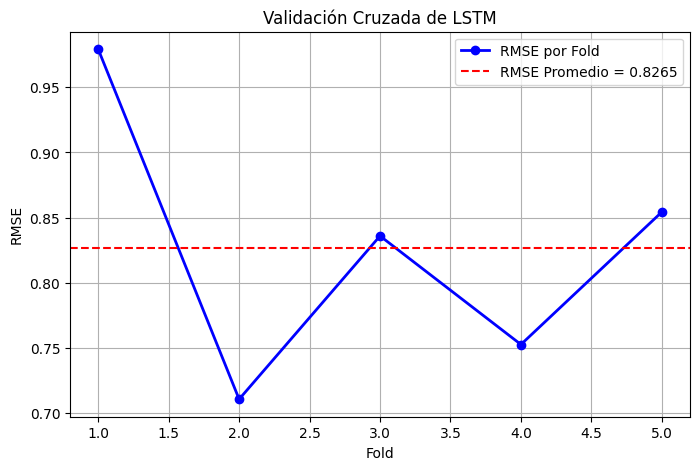

In [ ]:
import os
import matplotlib.pyplot as plt

directorio_destino = '/content/drive/MyDrive/Colab Notebooks/dataset/v_a_p_LSTM'
os.makedirs(directorio_destino, exist_ok=True)


plt.figure(figsize=(8, 5))

plt.plot(
    [1, 2, 3, 4, 5],
    rmse_folds,
    marker='o',
    linewidth=2,
    color='blue',
    label='RMSE por Fold'
)

plt.axhline(
    np.mean(rmse_folds),
    color='red',
    linestyle='--',
    label=f'RMSE Promedio = {np.mean(rmse_folds):.4f}'
)

plt.title('Validación Cruzada de LSTM')
plt.xlabel('Fold')
plt.ylabel('RMSE')
plt.grid(True)
plt.legend()

ruta_grafica = os.path.join(directorio_destino, 'grafica_rmse_folds.png')
plt.savefig(ruta_grafica, dpi=300, bbox_inches='tight')
print(f"Gráfica guardada exitosamente en:\n{ruta_grafica}\n")

plt.show()

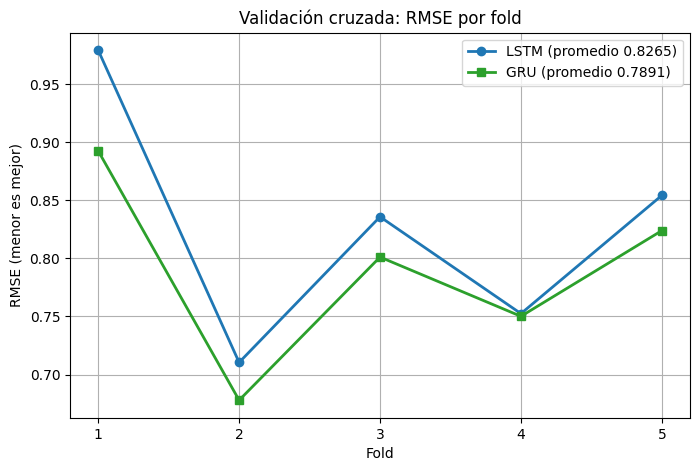

In [ ]:
# Grafica temporal

import pandas as pd, matplotlib.pyplot as plt, os
base = '/content/drive/MyDrive/Colab Notebooks/dataset'
g = pd.read_csv(f'{base}/v_a_p_GRU/resultados_gru.csv').iloc[:5]
l = pd.read_csv(f'{base}/v_a_p_LSTM/resultados_LSTM.csv').iloc[:5]
folds = range(1, 6)

plt.figure(figsize=(8, 5))
plt.plot(folds, l['RMSE'], marker='o', linewidth=2, color='#1f77b4',
         label=f"LSTM (promedio {l['RMSE'].mean():.4f})")
plt.plot(folds, g['RMSE'], marker='s', linewidth=2, color='#2ca02c',
         label=f"GRU (promedio {g['RMSE'].mean():.4f})")
plt.title('Validación cruzada: RMSE por fold')
plt.xlabel('Fold')
plt.ylabel('RMSE (menor es mejor)')
plt.xticks(list(folds))
plt.grid(True)
plt.legend()

destino = f'{base}/v_a_p_comparativa'
os.makedirs(destino, exist_ok=True)
plt.savefig(f'{destino}/grafica_cv_gru_vs_lstm.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
print(np.unique(y_train[:5]))
print("--------------")

for i in range(0, 50):
    print(y_train[i])

print("--------------")

for i in range(6900, 6959):
    print(y_train[i])

[-0.03535456  0.26830917]
--------------
0.2683091712022443
-0.0353545627435725
-0.0353545627435725
-0.0353545627435725
-0.0353545627435725
0.2302706142960802
0.4958957913357332
0.4958957913357332
0.4958957913357332
0.4958957913357332
1.001357293275267
1.001357293275267
1.001357293275267
1.001357293275267
1.001357293275267
2.341088161936429
3.6814637519010858
3.6814637519010858
3.6814637519010858
3.6814637519010858
-1.0720664187624125
-1.0720664187624125
-1.0720664187624125
-1.0720664187624125
-0.5279216386132203
0.0155784202324773
0.0155784202324773
0.0155784202324773
0.0155784202324773
0.837598082187714
1.6589730228394566
1.6589730228394566
1.6589730228394566
1.6589730228394566
0.3946745466871276
0.3946745466871276
0.3946745466871276
0.3946745466871276
0.3946745466871276
-0.8444797986289231
-0.8444797986289231
-0.8444797986289231
-0.8444797986289231
-0.603998752425548
-0.3641624275256672
-0.3641624275256672
-0.3641624275256672
-0.3641624275256672
0.0149336989289829
0.3946745466871276

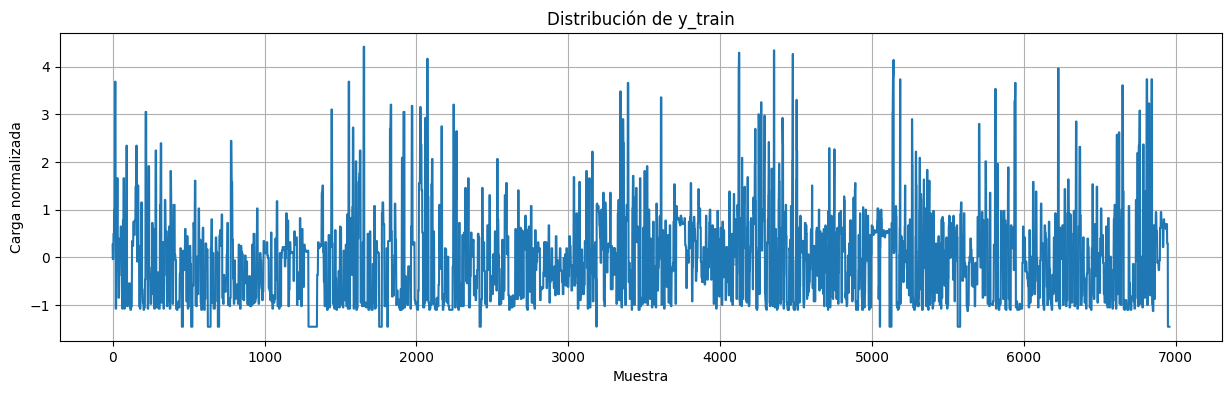

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,4))

plt.plot(y_train)

plt.title("Distribución de y_train")
plt.xlabel("Muestra")
plt.ylabel("Carga normalizada")

plt.grid(True)

plt.show()